# Marte: primer prototipo de mapas alineados

Preparación para buscar análogos terrestres: reunir los **7 TIFF disponibles** en una misma cuadrícula y visualizar sus variables. Todavía no calcula similitudes con la Tierra.

**Kernel:** selecciona `marte/.venv/bin/python` y ejecuta las celdas en orden. Dependencias en [requirements.txt](./requirements.txt).

Usaremos celdas globales de **1° (360 × 180)**, unos **59,3 km en el ecuador**. Es la escala del GHI disponible y sirve para una exploración regional; no resuelve un lugar de aterrizaje. El ancho este-oeste disminuye con la latitud.

In [6]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import rasterio as rio
from huggingface_hub import hf_hub_download
from rasterio.crs import CRS
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling

RAIZ = Path.cwd()
if (RAIZ / "marte").exists():
    RAIZ = RAIZ / "marte"
if Path(sys.prefix).resolve() != (RAIZ / ".venv").resolve():
    raise RuntimeError("Selecciona el kernel marte/.venv/bin/python")
SALIDA = RAIZ / "prototipo_alineado"
SALIDA.mkdir(exist_ok=True)
DATASET_REPO = "Renato-R-V/hspace-datasets"
print("Python:", sys.executable)

Python: /home/renato/Desktop/HSpace/marte/.venv/bin/python


## 1. Mapas disponibles

Se usan los minerales corregidos según la [auditoría previa](./auditoria_tiffs/INFORME.md).

- MOLA: altura sobre el areoide, en metros.
- GHI: **modelo simplificado**, media diaria para Ls = 18,9°, en W/m².
- OSP1/2/3 y BD2000: **indicadores espectrales adimensionales**, no porcentajes de mineral; cada OSP tiene su propia definición.
- Albedo TES: **albedo bolométrico adimensional** de MGS/TES. Los valores proceden del VICAR numérico de ASU; el canal alfa del PNG oficial aporta la máscara de cobertura. NoData se conserva como `NaN`. La cuantización de la fuente es de aproximadamente **0,000945**; no debe confundirse con su precisión científica. Fuente, conversión y compatibilidad en [albedo_ds.md](./docu/albedo_ds.md).

In [7]:
# Nombre: (archivo remoto/cacheado, unidad, paleta de colores)
def dataset(nombre):
    return hf_hub_download(
        repo_id=DATASET_REPO,
        repo_type="dataset",
        filename=f"marte/{nombre}",
    )

capas = {
    "Elevación MOLA": (dataset("1-Mars_MGS_MOLA_DEM_mosaic_global_463m.tif"), "m", "terrain"),
    "GHI modelado": (dataset("GHI_marte.tif"), "W/m²", "inferno"),
    "Albedo TES": (dataset("Albedo_marte.tif"), "adimensional", "cividis"),
    "Olivino OSP1": (dataset("olivine_osp1_equ_map.tiff"), "índice", "viridis"),
    "Olivino OSP2": (dataset("olivine_osp2_equ_map.tiff"), "índice", "viridis"),
    "Olivino OSP3": (dataset("olivine_osp3_equ_map.tiff"), "índice", "viridis"),
    "Piroxeno BD2000": (dataset("pyroxene_bd2000_equ_map.tiff"), "índice", "magma"),
}
for nombre, (archivo, unidad, _) in capas.items():
    with rio.open(archivo) as src:
        print(f"{nombre:18} {src.width:6} × {src.height:<6}  NoData={src.nodata}  [{unidad}]")

Elevación MOLA      46080 × 23040   NoData=-32768.0  [m]
GHI modelado          360 × 180     NoData=None  [W/m²]
Albedo TES           2880 × 1440    NoData=nan  [adimensional]
Olivino OSP1        14400 × 7200    NoData=-32768.0  [índice]
Olivino OSP2        14400 × 7200    NoData=-32768.0  [índice]
Olivino OSP3        14400 × 7200    NoData=-32768.0  [índice]
Piroxeno BD2000     14400 × 7200    NoData=-32768.0  [índice]


## 2. Cuadrícula marciana y alineación

El CRS objetivo es longitud/latitud **planetocéntrica de Marte**, esfera de radio 3.396.190 m, con longitudes −180° a 180°. No es WGS84 terrestre.

Se transforman MOLA y OMEGA desde sus CRS y georreferencias originales; TES usa la cuadrícula planetocéntrica documentada en su conversión. Se usa **media de valores válidos** para reducir resolución: así no se saltan detecciones pequeñas de OSP. Los desconocidos permanecen como `NaN`.

**Interpretación explícita del GHI:** su [generador](./origen_ds_gui_Y_albeolo/generar_ghi.py) calcula una geometría esférica, aunque escribió un CRS elipsoidal. Aquí se interpretan sus latitudes como planetocéntricas y se conservan exactamente sus celdas y valores; el TIFF original no se modifica.

Para cada mineral se guarda además la **fracción de píxeles con datos** dentro de la celda, entre 0 y 1. La media mineral está condicionada a esas detecciones: no representa la concentración media de toda la celda. La cobertura tampoco equivale a abundancia mineral.

In [8]:
crs_marte = CRS.from_string("+proj=longlat +R=3396190 +no_defs")
transformacion = from_origin(-180, 90, 1, 1)
forma = (180, 360)

def promediar(src, origen, nodata):
    destino = np.full(forma, np.nan, dtype="float32")
    reproject(
        source=origen, destination=destino,
        src_transform=src.transform, src_crs=src.crs, src_nodata=nodata,
        dst_transform=transformacion, dst_crs=crs_marte, dst_nodata=np.nan,
        resampling=Resampling.average, num_threads=2, warp_mem_limit=128,
    )
    return destino

datos, cobertura = {}, {}
with rio.Env(GDAL_PAM_ENABLED="NO"):
    for nombre, (archivo, _, _) in capas.items():
        print("Alineando:", nombre, flush=True)
        with rio.open(archivo) as src:
            if nombre == "GHI modelado":
                if src.shape != forma or not src.transform.almost_equals(transformacion):
                    raise ValueError("El GHI ya no coincide con la cuadrícula de 1°")
                datos[nombre] = src.read(1, masked=True).filled(np.nan).astype("float32")
            else:
                datos[nombre] = promediar(src, rio.band(src, 1), src.nodata)
            if nombre.startswith(("Olivino", "Piroxeno")):
                # 0 y 255 de la máscara son ambos datos válidos para este promedio.
                cobertura[nombre] = np.nan_to_num(promediar(src, src.read_masks(1), None)) / 255
print("Alineación terminada.")

Alineando: Elevación MOLA


Alineando: GHI modelado
Alineando: Albedo TES
Alineando: Olivino OSP1
Alineando: Olivino OSP2
Alineando: Olivino OSP3
Alineando: Piroxeno BD2000
Alineación terminada.


## 3. Datos preparados para los siguientes pasos

`cubo` tendrá forma **(7 variables, 180 filas, 360 columnas)**. Todas las bandas usan el mismo CRS, origen, extensión y tamaño de celda.

Se guardan dos GeoTIFF nuevos: los valores alineados y las cuatro fracciones de cobertura mineral. **No rellenamos los huecos con cero ni exigimos que los tres OSP coincidan**: eso descartaría muchas celdas útiles. Para una futura comparación, habrá que seleccionar variables equivalentes y considerar su cobertura.

In [9]:
cubo = np.stack(list(datos.values()))
for nombre, matriz in datos.items():
    validos = np.isfinite(matriz)
    print(f"{nombre:18} {validos.mean():7.2%} celdas con datos"
          f"  | rango {np.nanmin(matriz):.5g} a {np.nanmax(matriz):.5g}")
print("Forma del cubo:", cubo.shape)

def guardar(nombre_archivo, bandas, es_cobertura=False):
    with rio.open(
        SALIDA / nombre_archivo, "w", driver="GTiff",
        width=forma[1], height=forma[0], count=len(bandas),
        dtype="float32", crs=crs_marte, transform=transformacion,
        nodata=np.nan, compress="deflate", tiled=True,
    ) as dst:
        for i, (nombre, matriz) in enumerate(bandas.items(), 1):
            dst.write(matriz, i)
            dst.set_band_description(i, nombre)
            dst.update_tags(i, units="fracción válida" if es_cobertura else capas[nombre][1],
                            source_file=capas[nombre][0])
        dst.update_tags(grid="1 grado; Marte planetocentrico",
                        GHI_note="Ls=18.9; modelo esferico; celdas originales conservadas")

guardar("marte_1grado.tif", datos)
guardar("cobertura_minerales_1grado.tif", cobertura, es_cobertura=True)
print("Archivos guardados en:", SALIDA)

Elevación MOLA     100.00% celdas con datos  | rango -7491.2 a 20527
GHI modelado       100.00% celdas con datos  | rango 0 a 142.87
Albedo TES          97.78% celdas con datos  | rango 0.081033 a 0.32094
Olivino OSP1         7.98% celdas con datos  | rango 1.04 a 1.2932
Olivino OSP2         0.75% celdas con datos  | rango 1.04 a 1.2282
Olivino OSP3         1.02% celdas con datos  | rango 0.84004 a 1.0251
Piroxeno BD2000     61.32% celdas con datos  | rango 0.010003 a 0.082379
Forma del cubo: (7, 180, 360)
Archivos guardados en: /home/renato/Desktop/HSpace/marte/prototipo_alineado


## 4. Vista conjunta

Los siete paneles tienen la misma extensión; el gris indica ausencia de datos. Cada variable tiene su propia escala. El contraste entre percentiles 2 y 98 afecta **solo a la imagen**, no a los valores guardados. Las celdas minerales con poca cobertura se pueden ver ampliadas por la agregación: consultar siempre la cobertura antes de modelar.

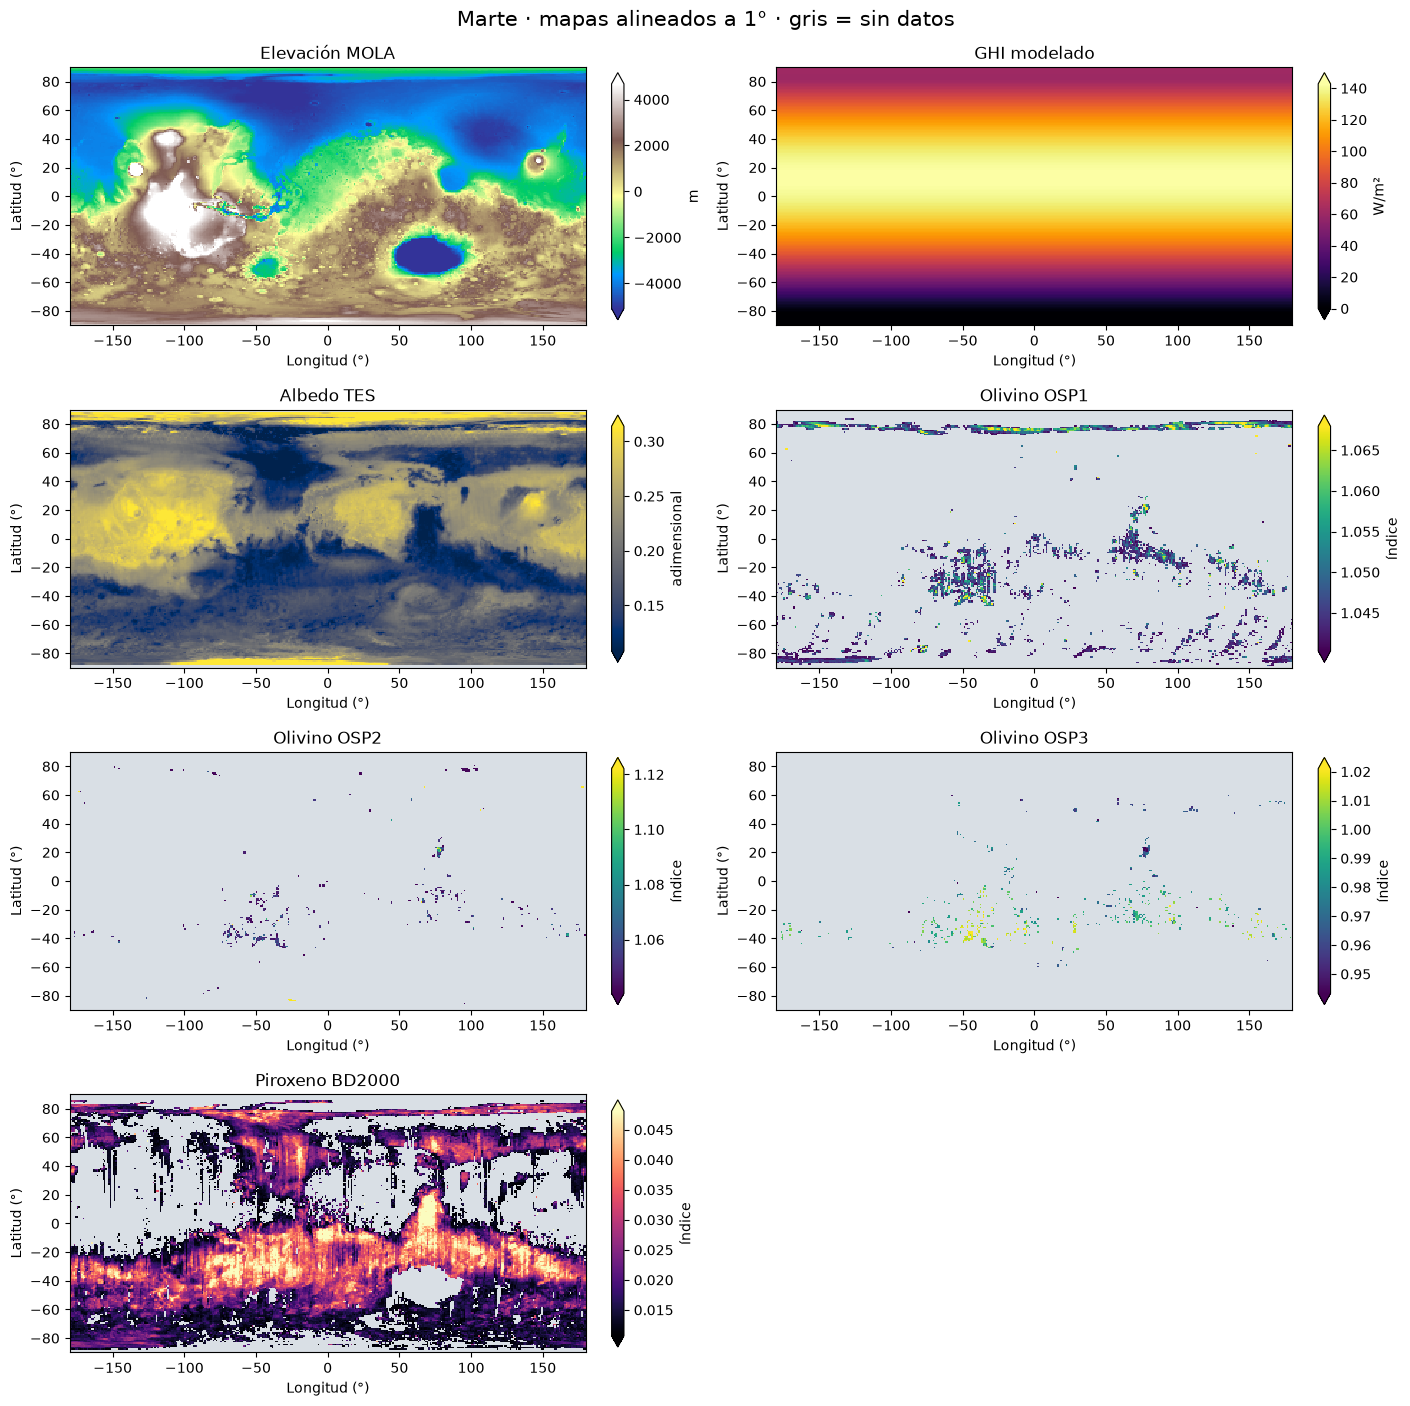

In [10]:
columnas = 2
filas = (len(datos) + columnas - 1) // columnas
fig, ejes = plt.subplots(filas, columnas, figsize=(14, 3.5 * filas),
                         squeeze=False, constrained_layout=True)
for ax, (nombre, matriz) in zip(ejes.flat, datos.items()):
    _, unidad, paleta = capas[nombre]
    cmap = plt.get_cmap(paleta).copy()
    cmap.set_bad("#d9dfe5")
    vmin, vmax = np.nanpercentile(matriz, [2, 98])
    im = ax.imshow(
        np.ma.masked_invalid(matriz), extent=(-180, 180, -90, 90),
        origin="upper", interpolation="nearest", cmap=cmap, vmin=vmin, vmax=vmax,
    )
    ax.set(title=nombre, xlabel="Longitud (°)", ylabel="Latitud (°)")
    fig.colorbar(im, ax=ax, label=unidad, shrink=.8, extend="both")
for ax in ejes.flat[len(datos):]:
    ax.set_visible(False)
fig.suptitle("Marte · mapas alineados a 1° · gris = sin datos", fontsize=15)
fig.savefig(SALIDA / "marte_conjunto.png", dpi=160)
plt.show()

### Próximo paso

Preparar variables terrestres equivalentes, con escala física comparable y unidades documentadas, antes de calcular semejanzas. **Un grado de Marte y un grado de la Tierra no representan la misma distancia.** Los índices OMEGA no se comparan directamente con porcentajes de rocas terrestres.

Este notebook conserva la advertencia de georreferenciación de MOLA de la [auditoría](./auditoria_tiffs/INFORME.md); no intenta corregir sus bordes sin una fuente independiente.

Referencia de implementación: [reproyección](https://rasterio.readthedocs.io/en/stable/topics/reproject.html) y [remuestreo](https://rasterio.readthedocs.io/en/stable/topics/resampling.html) de Rasterio.